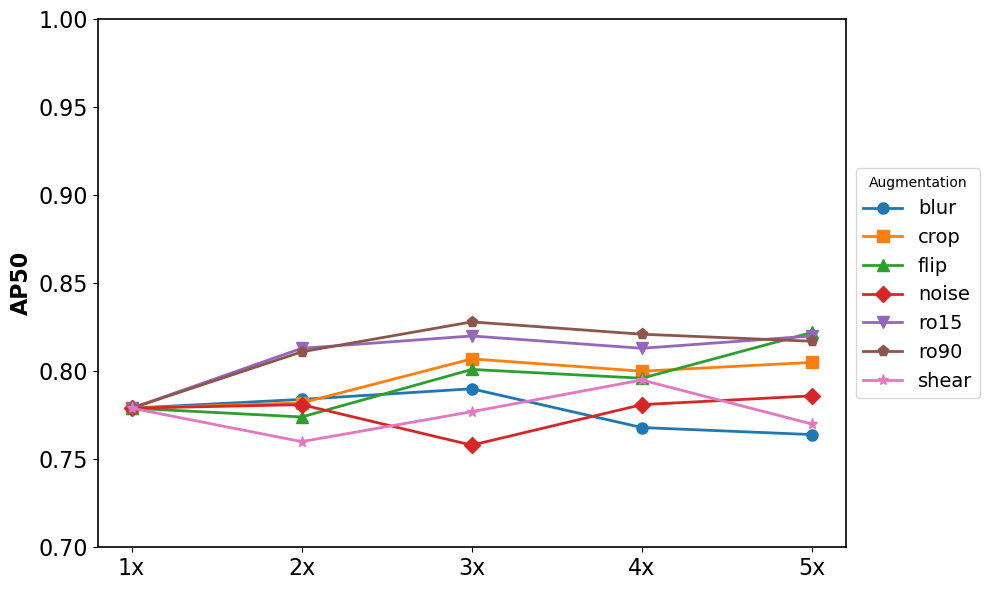

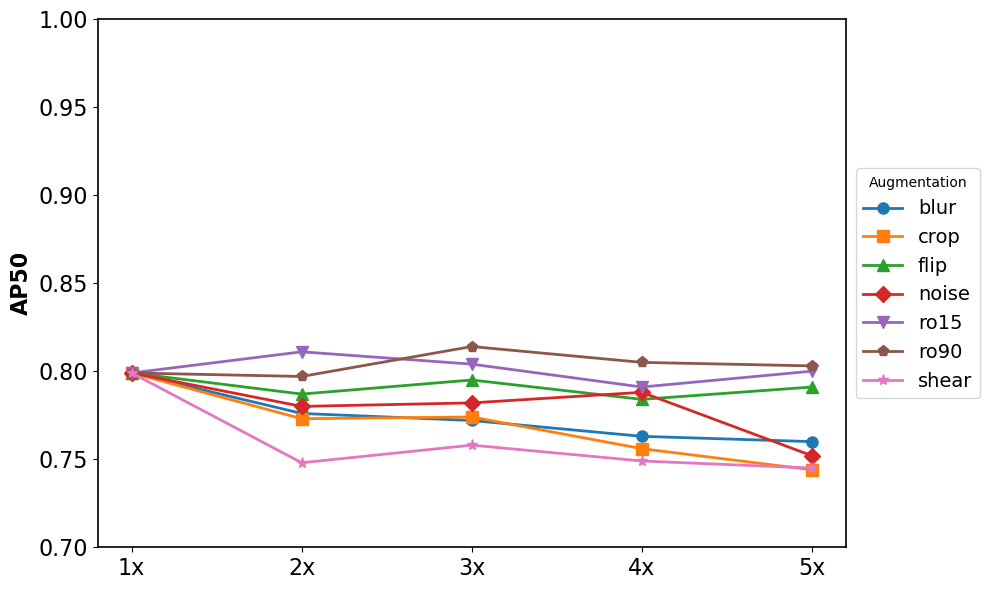

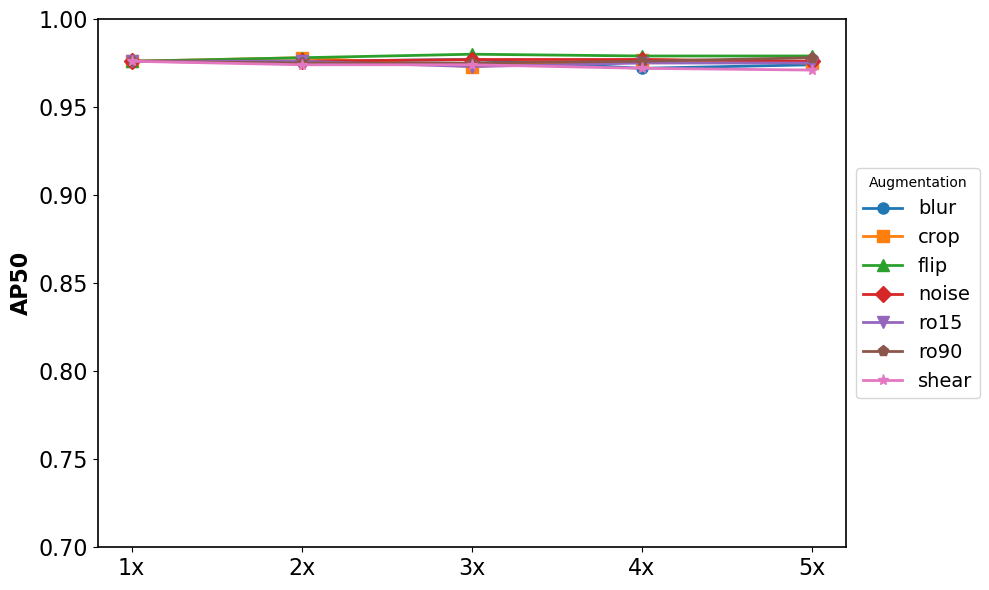

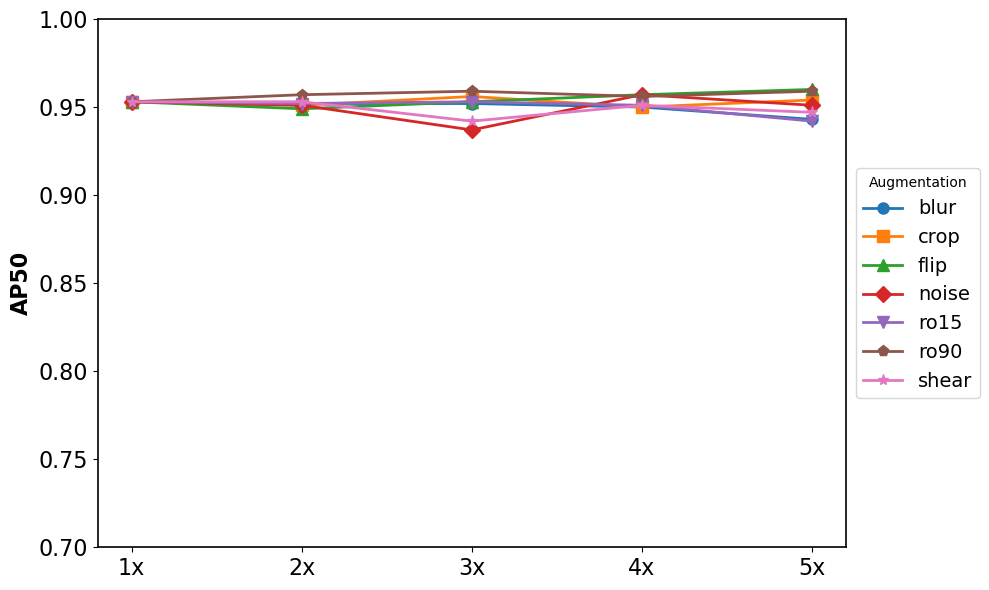

In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt


folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/full_data_1com_aug1to5' 
csv_files = glob.glob(os.path.join(folder_path, '*.csv'))
all_data = []

for file in csv_files:
    filename = os.path.basename(file)
    parts = filename.split('_')
    
    aug_method = parts[0]       
    multiplier = int(parts[1])  
    
    df = pd.read_csv(file)
    
    for index, row in df.iterrows():
        if row['Class'] in ['E', 'L', 'M', 'N']:
            all_data.append({
                'Class': row['Class'],
                'Augmentation': aug_method,
                'Multiplier': multiplier,
                'mAP50': row['mAP50']
            })

merged_df = pd.DataFrame(all_data)
target_classes = ['E', 'L', 'M', 'N']
plt.style.use('default') 

marker_list = ['o', 's', '^', 'D', 'v', 'p', '*']

for cls in target_classes:
    fig = plt.figure(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    
    ax = plt.gca()
    ax.set_facecolor('white')
    
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1.2)
        spine.set_visible(True)
    
    cls_data = merged_df[merged_df['Class'] == cls]
    
    aug_methods = cls_data['Augmentation'].unique()
    
    for i, aug in enumerate(aug_methods):
        aug_data = cls_data[cls_data['Augmentation'] == aug].sort_values(by='Multiplier')
        current_marker = marker_list[i % len(marker_list)]
        plt.plot(aug_data['Multiplier'], aug_data['mAP50'], marker=current_marker, label=aug, linewidth=2, markersize=8)
    
    # 그래프 꾸미기
    plt.ylabel('AP50', fontsize=16, fontweight='bold')
    plt.ylim(0.7, 1.0)
    plt.yticks(fontsize=16) 
    labels = ['1x', '2x', '3x', '4x','5x']
    plt.xticks([1, 2, 3, 4, 5], labels, fontsize=16) 
    plt.legend(title='Augmentation', loc='center left', bbox_to_anchor=(1, 0.5), fontsize=14)

    plt.tight_layout()

    os.makedirs('paper_figure', exist_ok=True) 
    plt.savefig(f'paper_figure/figure2_{cls}.png', dpi=300, bbox_inches='tight')
    
    plt.show()

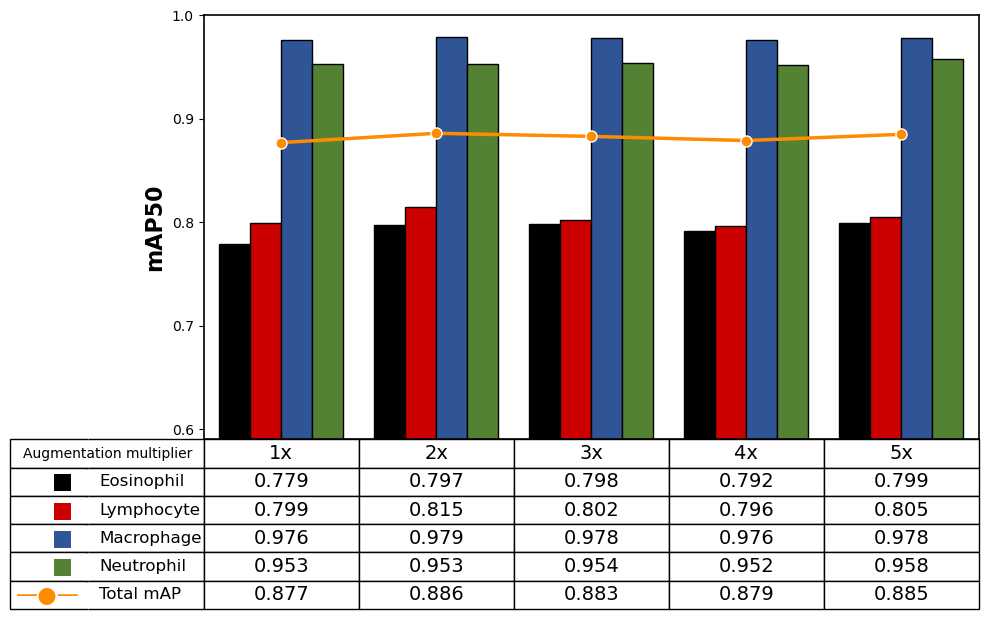

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt

folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/'
csv_files = glob.glob(os.path.join(folder_path, '*.csv'))

def extract_number(filepath):
    filename = os.path.basename(filepath)
    numbers = re.findall(r'\d+', filename) 
    return int(numbers[0]) if numbers else 0

csv_files = sorted(csv_files, key=extract_number)

mAP50_data = {'E': [], 'L': [], 'M': [], 'N': [], 'all': []}
columns = []

for file_path in csv_files:
    multiplier = extract_number(file_path)
    if multiplier == 1:
        columns.append('1x')
    else:
        columns.append(f'{multiplier}x')
        
    df = pd.read_csv(file_path)
    
    for cls in ['E', 'L', 'M', 'N', 'all']:
        val = df[df['Class'] == cls]['mAP50'].values[0]
        mAP50_data[cls].append(val)


plt.style.use('default') 
fig, ax = plt.subplots(figsize=(10, 8)) 

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

x = np.arange(len(columns))
width = 0.2  

color_E = 'black'
color_L = '#CC0000'  
color_M = '#2F5597'  
color_N = '#548235'  
color_Total = '#FF8C00' 

ax.bar(x - 1.5*width, mAP50_data['E'], width, color=color_E, edgecolor='black')
ax.bar(x - 0.5*width, mAP50_data['L'], width, color=color_L, edgecolor='black')
ax.bar(x + 0.5*width, mAP50_data['M'], width, color=color_M, edgecolor='black')
ax.bar(x + 1.5*width, mAP50_data['N'], width, color=color_N, edgecolor='black')

ax.plot(x, mAP50_data['all'], color=color_Total, marker='o', markerfacecolor=color_Total, markeredgecolor='white', markersize=8, linewidth=2.5)

ax.set_ylabel('mAP50', fontsize=16, fontweight='bold')
ax.set_ylim(0.59, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])

ax.set_xticks([]) 
ax.tick_params(axis='x', which='both', bottom=False, top=False)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

ax.set_xlim(-0.5, len(columns) - 0.5)

table_columns = ['', 'Augmentation multiplier'] + columns

def format_data(data_list):
    return [f"{v:.3f}" for v in data_list]

cell_text = [
    ['■ ', 'Eosinophil'] + format_data(mAP50_data['E']),
    ['■ ', 'Lymphocyte'] + format_data(mAP50_data['L']),
    ['■ ', 'Macrophage'] + format_data(mAP50_data['M']),
    ['■ ', 'Neutrophil'] + format_data(mAP50_data['N']),
    ['—●—', 'Total mAP'] + format_data(mAP50_data['all'])
]

widths = [0.08, 0.12] + [0.16] * len(columns)

table = ax.table(cellText=cell_text, 
                 colLabels=table_columns, 
                 loc='bottom', 
                 cellLoc='center', 
                 colWidths=widths,
                 bbox=[-0.25, -0.4, 1.25, 0.4]) 

table.auto_set_font_size(False)
table.set_fontsize(14)

colors = [color_E, color_L, color_M, color_N, color_Total]

for (row, col), cell in table.get_celld().items():
    if row == 0: 
        cell.set_text_props(fontweight='normal')
        if col == 0: 
            cell.visible_edges = 'LBT' 
        elif col == 1: 
            cell.visible_edges = 'RBT'
            cell.set_text_props(fontsize=10, ha='right') 
        else:
            cell.set_text_props(fontsize=14) 
            
    elif row > 0: 
        if col == 0:
            cell.set_text_props(color=colors[row-1], fontweight='normal', fontsize=16)
            cell.get_text().set_ha('right')
            cell.visible_edges = 'LBT'
        elif col == 1:
            cell.set_text_props(fontweight='normal', fontsize=12)
            cell.get_text().set_ha('left')
            cell.visible_edges = 'RBT'

plt.subplots_adjust(bottom=0.35) 
plt.savefig('figure1_bar_and_line_color.png', dpi=300, bbox_inches='tight')
plt.show()

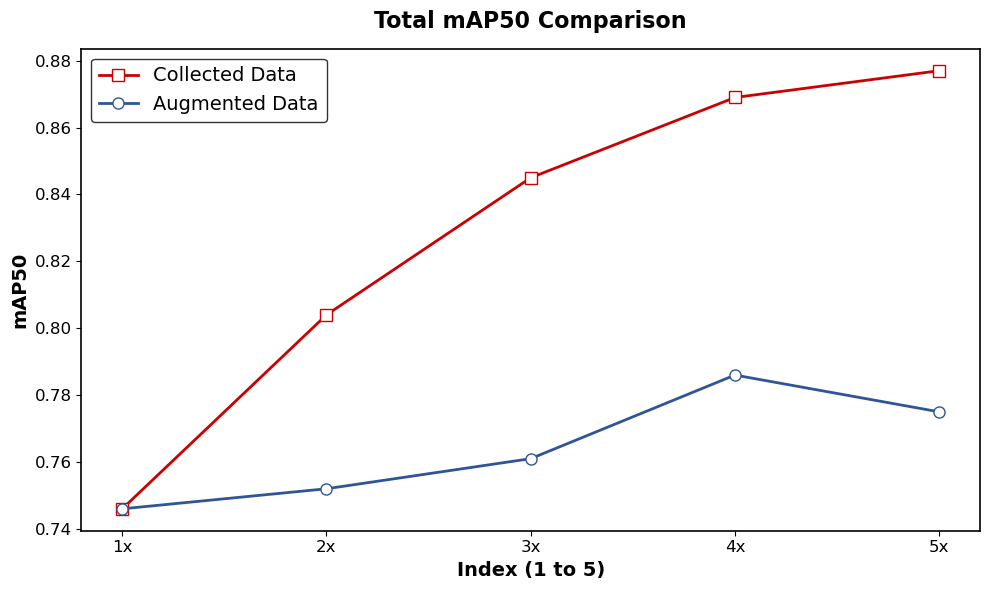

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/'

group1_x, group1_y = [], []  
group2_x, group2_y = [], []  

def load_data(file_pattern, x_list, y_list):
    for i in range(1, 6):
        file_name = file_pattern.format(i)
        file_path = os.path.join(folder_path, file_name)
        
        if os.path.exists(file_path):
            df = pd.read_csv(file_path)
            val = df[df['Class'] == 'all']['mAP50'].values[0]
            x_list.append(i)  
            y_list.append(val)

# 변경된 파일명에 맞춰 각각의 데이터 로드
load_data('full_aug{}_data.csv', group1_x, group1_y)
load_data('cp{}_data.csv', group2_x, group2_y)

plt.style.use('default') 
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.plot(group2_x, group2_y, color='#CC0000', marker='s', markerfacecolor='white', markeredgecolor='#CC0000', markersize=8, linewidth=2, label='Collected Data')
ax.plot(group1_x, group1_y, color='#2F5597', marker='o', markerfacecolor='white', markeredgecolor='#2F5597', markersize=8, linewidth=2, label='Augmented Data')

ax.set_title('Total mAP50 Comparison', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Index (1 to 5)', fontsize=14, fontweight='bold')
ax.set_ylabel('mAP50', fontsize=14, fontweight='bold')
plt.xticks(ticks=[1, 2, 3, 4, 5], labels=['1x', '2x', '3x', '4x', '5x'])

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

plt.tick_params(axis='both', which='major', labelsize=12)
ax.legend(loc='best', frameon=True, edgecolor='black', fontsize=14)

plt.tight_layout()
plt.savefig('figure8_total_map_comparison_updated.png', dpi=300, bbox_inches='tight')
plt.show()

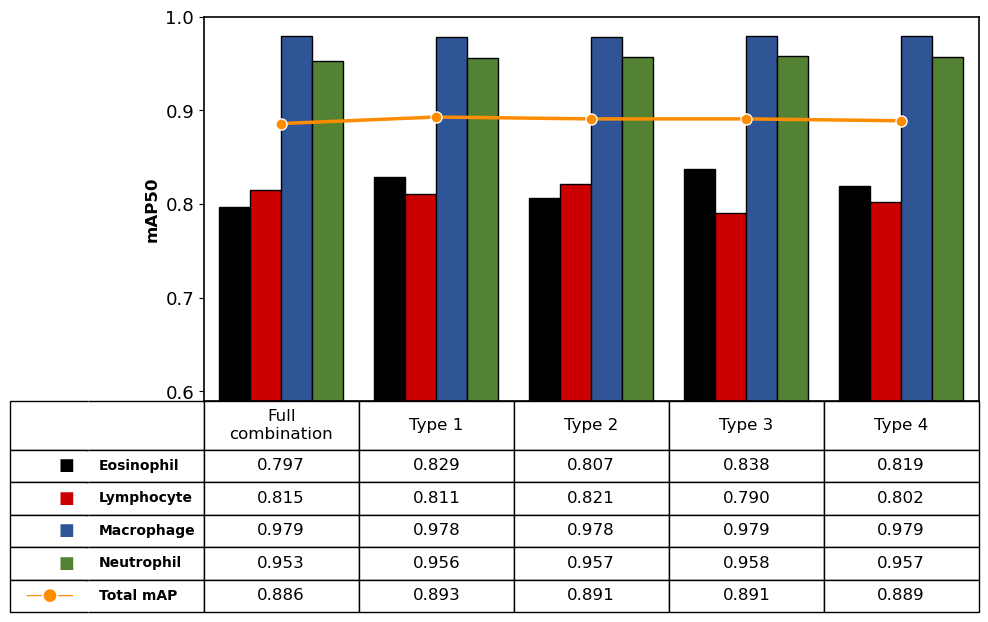

In [ ]:
import os
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt

base_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell'


folder_path_1 = os.path.join(base_path, '')  
folder_path_2 = os.path.join(base_path, '')  

custom_labels = [
    "Full\ncombination",
    "Type 1",
    "Type 2",
    "Type 3",
    "Type 4"
]

files_to_plot = [
    (os.path.join(folder_path_2, 'full_2_data.csv'), custom_labels[0]),
    (os.path.join(folder_path_1, '1st_aug2_data.csv'), custom_labels[1]),
    (os.path.join(folder_path_1, '2nd_aug2_data.csv'), custom_labels[2]),
    (os.path.join(folder_path_1, '3rd_aug2_data.csv'), custom_labels[3]),
    (os.path.join(folder_path_1, '4th_aug2_data.csv'), custom_labels[4])
]

mAP50_data = {'E': [], 'L': [], 'M': [], 'N': [], 'all': []}
columns = [label for _, label in files_to_plot]

for filepath, _ in files_to_plot:
    df = pd.read_csv(filepath)
    class_col = 'Class' if 'Class' in df.columns else 'class'
    map_col = 'mAP50' if 'mAP50' in df.columns else 'mAP@0.5'
    
    for cls in ['E', 'L', 'M', 'N', 'all']:
        val = df[df[class_col] == cls][map_col].values[0]
        mAP50_data[cls].append(val)

plt.style.use('default') 
fig, ax = plt.subplots(figsize=(10, 8)) 

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

x = np.arange(len(columns))
width = 0.2  

color_E = 'black'
color_L = '#CC0000'  
color_M = '#2F5597'  
color_N = '#548235'  
color_Total = '#FF8C00' 

ax.bar(x - 1.5*width, mAP50_data['E'], width, color=color_E, edgecolor='black')
ax.bar(x - 0.5*width, mAP50_data['L'], width, color=color_L, edgecolor='black')
ax.bar(x + 0.5*width, mAP50_data['M'], width, color=color_M, edgecolor='black')
ax.bar(x + 1.5*width, mAP50_data['N'], width, color=color_N, edgecolor='black')

ax.plot(x, mAP50_data['all'], color=color_Total, marker='o', markerfacecolor=color_Total, markeredgecolor='white', markersize=8, linewidth=2.5)

ax.set_ylabel('mAP50', fontsize=12, fontweight='bold')
ax.set_ylim(0.59, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.tick_params(axis='y', labelsize=13)

ax.set_xticks([]) 
ax.tick_params(axis='x', which='both', bottom=False, top=False)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

ax.set_xlim(-0.5, len(columns) - 0.5)

table_columns = ['', ''] + columns

def format_data(data_list):
    return [f"{v:.3f}" for v in data_list]

cell_text = [
    ['■ ', 'Eosinophil'] + format_data(mAP50_data['E']),
    ['■ ', 'Lymphocyte'] + format_data(mAP50_data['L']),
    ['■ ', 'Macrophage'] + format_data(mAP50_data['M']),
    ['■ ', 'Neutrophil'] + format_data(mAP50_data['N']),
    ['—●— ', 'Total mAP'] + format_data(mAP50_data['all'])
]

widths = [0.08, 0.12] + [0.16] * len(columns)

table = ax.table(cellText=cell_text, 
                 colLabels=table_columns, 
                 loc='bottom', 
                 cellLoc='center', 
                 colWidths=widths,
                 bbox=[-0.25, -0.55, 1.25, 0.55]) 

table.auto_set_font_size(False)
table.set_fontsize(12) 

colors = [color_E, color_L, color_M, color_N, color_Total]

for (row, col), cell in table.get_celld().items():
    if row == 0: 
        cell.set_text_props(fontweight='normal')
        if col == 0: cell.visible_edges = 'LBT' 
        if col == 1: cell.visible_edges = 'RBT' 
    elif row > 0: 
        if col == 0:
            cell.set_text_props(color=colors[row-1], fontweight='normal', fontsize=12)
            cell.get_text().set_ha('right')
            cell.visible_edges = 'LBT'
        elif col == 1:
            cell.set_text_props(fontweight='bold', fontsize=10)
            cell.get_text().set_ha('left')
            cell.visible_edges = 'RBT'


cell_dict = table.get_celld()
top_y = 0.0 

for row in range(6): 
    for col in range(len(columns) + 2):
        if (row, col) in cell_dict:
            cell = cell_dict[(row, col)]
            
            x = cell.get_x()
            w = cell.get_width()
            
            if row == 0:
                h = 0.15 
                y = top_y - h
            else:
                h = 0.10 
                y = top_y - 0.20 - (row * 0.05) 
                
            cell.set_bounds(x, y, w, h)

plt.subplots_adjust(bottom=0.4) 
plt.savefig('figure3_swapped_data.png', dpi=300, bbox_inches='tight')
plt.show()

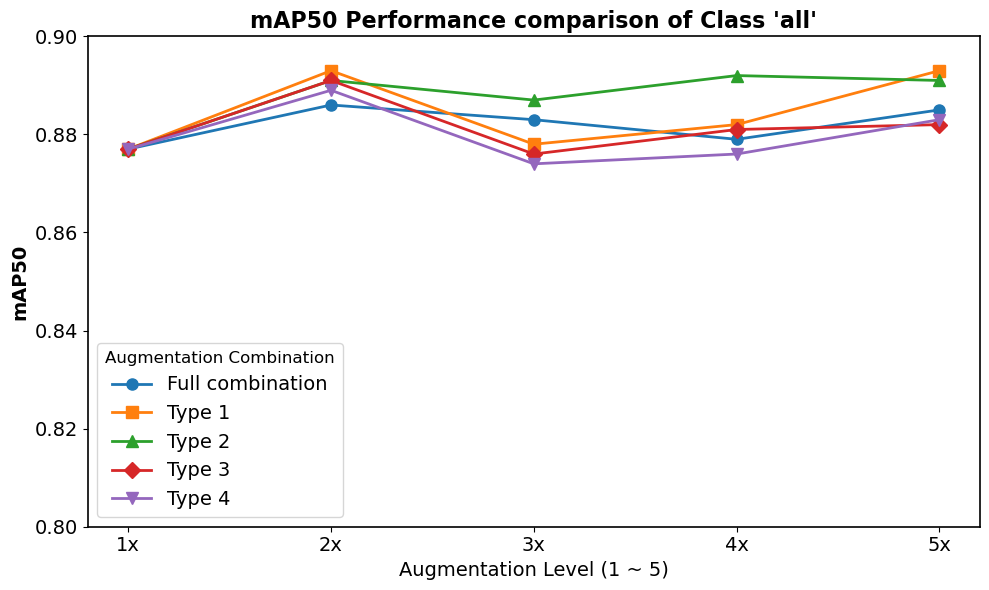

In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

base_folder = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell'

folder_full = os.path.join(base_folder, '')
folder_aug = os.path.join(base_folder, '')

all_data = []

full_csv_files = glob.glob(os.path.join(folder_full, 'full_*_data.csv'))

for file in full_csv_files:
    filename = os.path.basename(file)
    multiplier = int(filename.split('_')[1])
    
    df = pd.read_csv(file)
    
    map50_value = df[df['Class'] == 'all']['mAP50'].values[0]
    all_data.append({'Group': 'full', 'Multiplier': multiplier, 'mAP50': map50_value})

aug_csv_files = glob.glob(os.path.join(folder_aug, '*_aug*.csv'))

for file in aug_csv_files:
    filename = os.path.basename(file)
    group = filename.split('_')[0] 
    multiplier_str = filename.split('_')[1].replace('aug', '').replace('.csv', '')
    multiplier = int(multiplier_str)
    
    df = pd.read_csv(file)
    map50_value = df[df['Class'] == 'all']['mAP50'].values[0]
    all_data.append({'Group': group, 'Multiplier': multiplier, 'mAP50': map50_value})


df_all = pd.DataFrame(all_data)
groups = ['full', '1st', '2nd', '3rd', '4th']

custom_labels = {
    'full': "Full combination",
    '1st': "Type 1",
    '2nd': "Type 2",
    '3rd': "Type 3",
    '4th': "Type 4"
}

plt.figure(figsize=(10, 6))
ax = plt.gca()
ax.set_facecolor('white')

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

custom_markers = {
    'full': 'o', 
    '1st': 's',  
    '2nd': '^',  
    '3rd': 'D',  
    '4th': 'v'   
}

for group in groups:
    group_data = df_all[df_all['Group'] == group].sort_values(by='Multiplier')
    plt.plot(group_data['Multiplier'], group_data['mAP50'], marker=custom_markers[group], 
             label=custom_labels[group], linewidth=2, markersize=8)

plt.title("mAP50 Performance comparison of Class 'all'", fontsize=16, fontweight='bold')
plt.xlabel('Augmentation Level (1 ~ 5)', fontsize=14)
plt.ylabel('mAP50', fontsize=14, fontweight='bold')

labels = ['1x', '2x', '3x', '4x','5x']
plt.xticks([1, 2, 3, 4, 5], labels, fontsize=14) 
plt.ylim(0.8, 0.9) 
plt.tick_params(axis='both', which='major', labelsize=14)
plt.legend(title='Augmentation Combination', loc='lower left', fontsize=14, title_fontsize=12)
plt.tight_layout()
plt.savefig('paper_figure/figure5a.png', dpi=300, bbox_inches='tight')

plt.show()

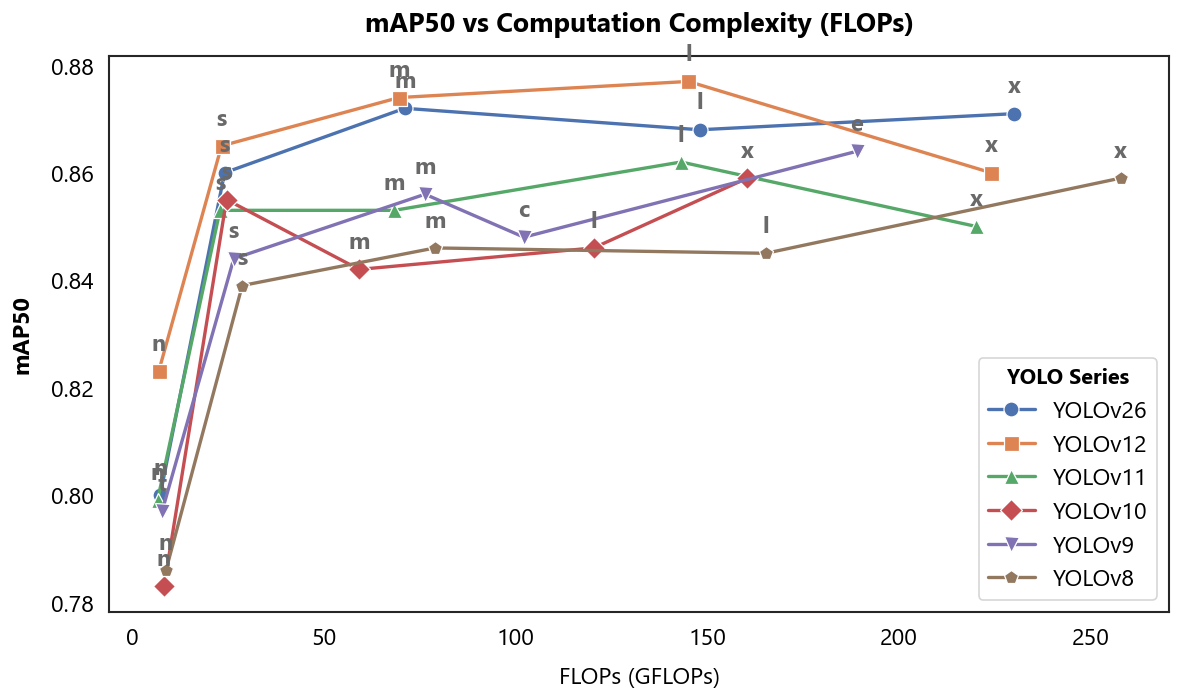

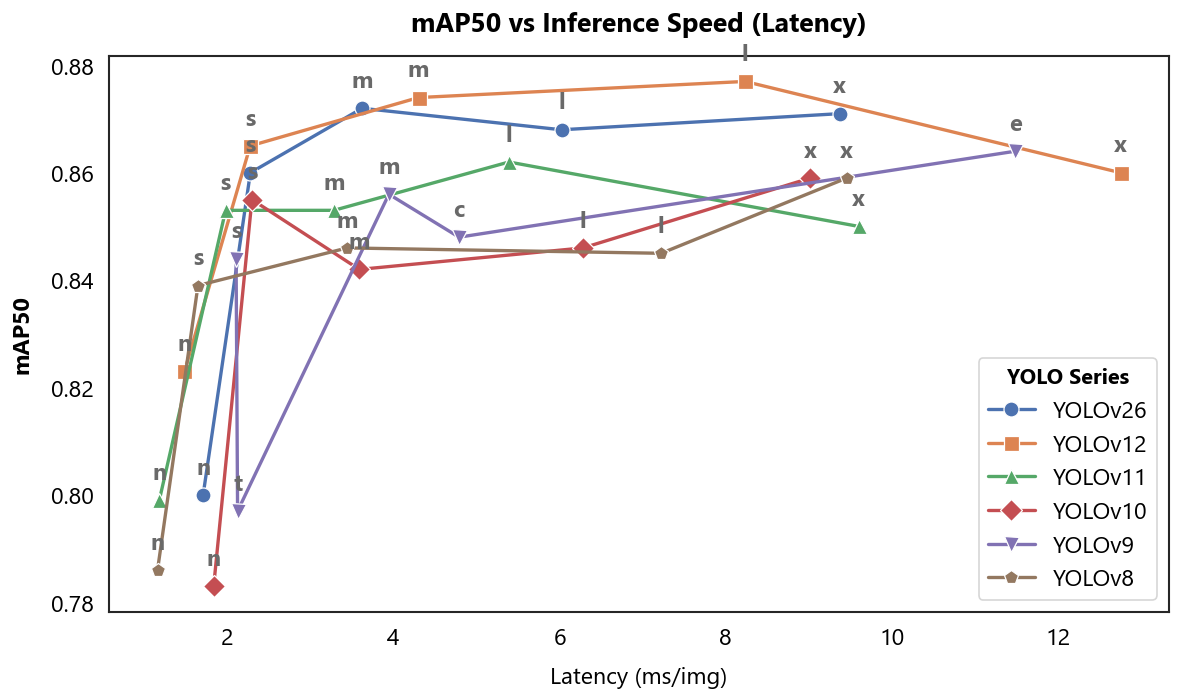

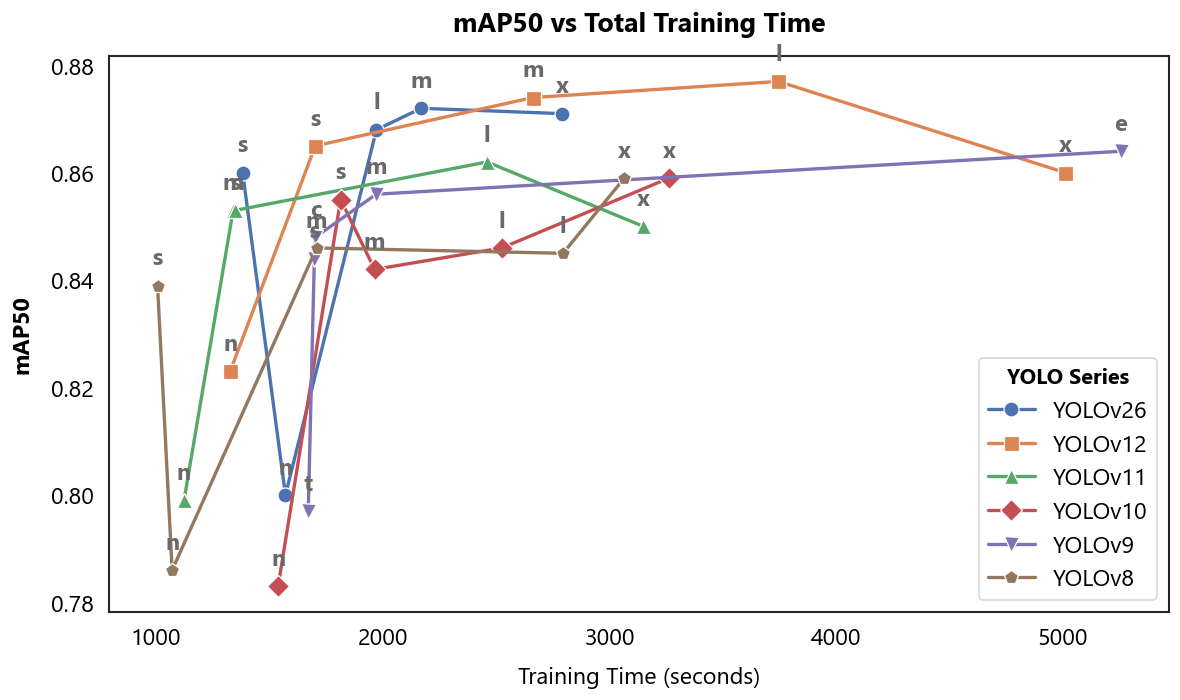

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

base_dir = Path(r"C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/")
summary_csv_path = base_dir / "" 
flops_json_path = base_dir / ""

with open(flops_json_path, "r", encoding="utf-8") as f:
    flops_dict = json.load(f)

df = pd.read_csv(summary_csv_path)

df['FLOPs(G)'] = df['Model'].map(flops_dict)

def parse_model_info(model_name):
    name = model_name.replace('.pt', '')
    size = name[-1]     
    series = name[:-1]   
    
    if series.startswith('yolo') and not series.startswith('yolov'):
        series = series.replace('yolo', 'YOLOv')
    elif series.startswith('yolov'):
        series = series.replace('yolov', 'YOLOv')
        
    return pd.Series([series, size])

df[['Series', 'Size']] = df['Model'].apply(parse_model_info)

size_order = ['n', 't', 's', 'm', 'c', 'l', 'x', 'e']
df['Size'] = pd.Categorical(df['Size'], categories=size_order, ordered=True)
df = df.sort_values(by=['Series', 'Size'])

sns.set_theme(style="white")
plt.rcParams['font.family'] = 'Segoe UI'
plt.rcParams['axes.unicode_minus'] = False

plt.rcParams.update({
    'font.size': 12,
    'text.color': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black'
})

x_metrics = {
    'FLOPs(G)': ('FLOPs (GFLOPs)', 'mAP50 vs Computation Complexity (FLOPs)'),
    'Inference_Time(ms/img)': ('Latency (ms/img)', 'mAP50 vs Inference Speed (Latency)'),
    'Train_Time(sec)': ('Training Time (seconds)', 'mAP50 vs Total Training Time')
}

legend_order = ['YOLOv26', 'YOLOv12', 'YOLOv11', 'YOLOv10', 'YOLOv9', 'YOLOv8']
marker_list = ['o', 's', '^', 'D', 'v', 'p'] 

for x_col, (x_label, title) in x_metrics.items():
    plt.figure(figsize=(10, 6), dpi=120)
    
    sns.lineplot(
        data=df, 
        x=x_col, 
        y='mAP50', 
        hue='Series', 
        style='Series',          
        hue_order=legend_order,
        style_order=legend_order, 
        markers=marker_list,      
        dashes=False,             
        markersize=9, 
        linewidth=2,
    )

    for i, row in df.dropna(subset=[x_col, 'mAP50']).iterrows():
        plt.text(
            row[x_col], 
            row['mAP50'] + 0.003,
            row['Size'], 
            fontsize=14, 
            ha='center', 
            va='bottom',
            weight='bold',
            color='dimgray',
            alpha=1.0
        )
        

    plt.title(title, fontsize=16, pad=15, weight='bold', color='black')
    plt.xlabel(x_label, fontsize=14, labelpad=10, color='black')
    plt.ylabel('mAP50', fontsize=14, labelpad=10, color='black', fontweight='bold')
    plt.xticks(fontsize=14) 
    plt.yticks(fontsize=14) 
    plt.tick_params(colors='black')
    
    legend = plt.legend(
        title="YOLO Series", 
        loc='lower right', 
        frameon=True, 
        fontsize=14,
        title_fontsize=13
    )
    
    plt.setp(legend.get_title(), color='black', weight='bold')
    for text in legend.get_texts():
        text.set_color('black')

    plt.tight_layout()
    
    save_filename = f"plot_mAP50_vs_{x_col.split('(')[0]}.png"
    plt.savefig(save_filename, dpi=300, bbox_inches='tight')
    plt.show()